10

### 1.setup

In [2]:

from dotenv import load_dotenv
import os

In [8]:
load_dotenv()  # Load environment variables from .env file


True

In [9]:
from langchain_groq import ChatGroq

In [10]:
llm=ChatGroq(model="openai/gpt-oss-20b")


In [11]:
res=llm.invoke("hello")
res.content

'Hello! 👋 How can I help you today?'

#### 2.State - Global State to pass the data between the all nodes

In [12]:
from pydantic import BaseModel


In [18]:
class Userstate(BaseModel):
    name: str=""
    age: int=0
    email: str=""
 
state=Userstate(name="prabesh")  


In [19]:
state

Userstate(name='prabesh', age=0, email='')

#### 2.1) Building the graph using the Langgraph

In [21]:
from langgraph.graph import StateGraph , END ,START 
from pydantic import BaseModel

In [22]:
class Mystate(BaseModel):
    messages: str=""
    


In [41]:
def greet(state:Mystate):
    "I am the geet node ..."
    state.messages="hello! Good morning"
    return state



In [42]:
graph =StateGraph(Mystate)
graph.add_node("greet", greet)

In [43]:
graph.add_edge(START, "greet")
graph.add_edge("greet", END)

In [44]:
final_graph=graph.compile()

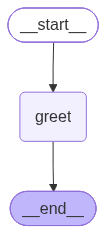

In [45]:
final_graph

In [46]:
res=final_graph.invoke({"messages":"hello"})

In [47]:
res

{'messages': 'hello! Good morning'}

#### 2.2) Multi node graph

In [49]:
from random import randint


In [50]:
class ReviewState(BaseModel):
    text: str=""
    score: int=0
    comments: str=""

In [51]:
def score(state:ReviewState)->ReviewState:
    state.score=randint(1,10)
    return state

In [52]:
def commenter(state:ReviewState)->ReviewState:
    if state.score>5:
        state.comments="well done! that's a nice score"
    else:
        state.comments="that's a bad score"
    return state

In [61]:
graph=StateGraph(ReviewState)


In [62]:
graph.add_node("score", score)
graph.add_node("commenter", commenter)


In [64]:
graph.add_edge(START, "score")
graph.add_edge("score", "commenter")
graph.add_edge("commenter", END)

In [65]:
final_graph=graph.compile()

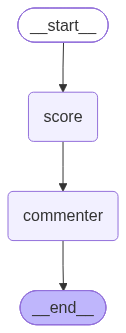

In [66]:
final_graph

In [77]:
res=final_graph.invoke({})

In [78]:
res

{'text': '', 'score': 6, 'comments': "well done! that's a nice score"}

#### 3 `add_messages` reducer - for chat history